# 04 · Transfer probe: train on NewsCLIPpings, test on targets

Published systems train on NewsCLIPpings and test on the target. Here the LAYA-Vision checkpoint stays frozen, its 576-dimensional internal state for each image-caption pair is recorded, and a logistic-regression probe is trained on those features. The weights of the checkpoint never change. The NewsCLIPpings test split was read once, after the protocol was frozen, so it is a held-out result.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

ROOT = Path.cwd().resolve().parents[1]
assert (ROOT / "data").is_dir(), ROOT
OUT = ROOT / "MIDTERM_PRETRAINED_BASELINE"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
PROBE_DIR = ROOT / "data/processed/protocol/ncp_transfer_probe_v1"


def load_json(path):
    with open(path, encoding="utf-8") as handle:
        return json.load(handle)


def plain(text):
    return str(text).replace("\u2014", ",").replace("\u2013", "-")


probe = load_json(PROBE_DIR / "full_probe.json")
pilot = load_json(PROBE_DIR / "pilot_probe.json")
full_run = load_json(PROBE_DIR / "full" / "run.json")
verite_run = load_json(PROBE_DIR / "verite" / "run.json")
supplement = load_json(ROOT / "dashboard/published_supplement.json")
references = load_json(ROOT / "data/workflows/baseline_study/published_references.json")

for name, obj in [("full_probe", probe), ("pilot_probe", pilot), ("full run", full_run),
                  ("verite run", verite_run), ("published_supplement", supplement),
                  ("published_references", references)]:
    print(name, "keys:", sorted(obj.keys()))

full_probe keys: ['bootstrap', 'feature_used', 'grid', 'integrity_gate', 'lambdas', 'mode', 'newsclippings_test', 'protocol', 'reproducibility', 'rows', 'runs', 'selected_lambda', 'source_sha256', 'verite_true_vs_ooc', 'zero_shot_val_accuracy']
pilot_probe keys: ['bootstrap', 'feature_used', 'features', 'grid', 'integrity_gate', 'label', 'mode', 'protocol', 'rows', 'selected_lambda', 'source_sha256', 'test_rows_read', 'val_clusters', 'verite_rows_read', 'zero_shot_val']
full run keys: ['archive_members_read', 'args', 'decode_failures', 'feature_dim', 'feature_layout', 'featurized_rows', 'feeders', 'feeders_reported', 'images_missing', 'images_seen', 'images_stored', 'inference_seconds', 'laya_version', 'misaligned_headers', 'missing_examples', 'new_training', 'protocol', 'reader_model', 'reconnects', 'rows_per_inference_second', 'source_sha256', 'splits', 'straddled_range_end', 'torch_threads', 'train_sample_seed', 'wall_seconds', 'wanted_images', 'wanted_rows']
verite run keys: ['args

## Run and integrity gates

In [2]:
gate = probe["integrity_gate"]
repro = probe["reproducibility"]
run_rows = [
    ("NewsCLIPpings rows featurized / wanted (train + test)",
     f"{full_run['featurized_rows']:,} / {full_run['wanted_rows']:,}"),
    ("Images missing / decode failures",
     f"{full_run['images_missing']:,} / {full_run['decode_failures']:,}"),
    ("Readers reported / total",
     f"{full_run['feeders_reported']} / {full_run['feeders']}"),
    ("Reconnects", f"{full_run['reconnects']}"),
    ("Range-boundary cuts", f"{full_run['straddled_range_end']}"),
    ("Device", full_run["args"]["device"]),
    ("Wall time (hours)", f"{full_run['wall_seconds'] / 3600:.2f}"),
    ("VERITE rows featurized / wanted",
     f"{verite_run['featurized_rows']:,} / {verite_run['rows_wanted']:,}"),
    ("Rows used: train / validation / test / VERITE",
     " / ".join(f"{probe['rows'][k]:,}" for k in ["train", "val", "test", "verite"])),
    ("Integrity gate: validation rows checked", f"{gate['val_rows_checked']:,}"),
    ("Integrity gate: max absolute difference", f"{gate['max_abs_difference']:.4f}"),
    ("Integrity gate: tolerance", f"{gate['tolerance']}"),
    ("Integrity gate: passed", str(gate["passed"])),
    ("Reproducibility: pilot train rows found in full run",
     f"{repro['found_in_full_run']:,} / {repro['pilot_train_rows']:,}"),
    ("Reproducibility: max feature difference", f"{repro['max_abs_feature_difference']:.2e}"),
    ("Reproducibility: passed", str(repro["passed"])),
]
run_table = pd.DataFrame(run_rows, columns=["Item", "Value"])
display(run_table.set_index("Item"))

,Value
Item,
NewsCLIPpings rows featurized / wanted (train + test),"78,336 / 78,336"
Images missing / decode failures,0 / 0
Readers reported / total,12 / 12
Reconnects,0
Range-boundary cuts,11
Device,mps
Wall time (hours),4.58
VERITE rows featurized / wanted,663 / 663
Rows used: train / validation / test / VERITE,"71,072 / 7,024 / 7,264 / 663"


## Regularization

In [3]:
selected = probe["selected_lambda"]
reg_rows = []
for g in probe["grid"]:
    lam = g["lambda"]
    vlo, vhi = g["val"]["accuracy_95"]
    dlo, dhi = g["val_minus_zero_shot"]["accuracy_95"]
    reg_rows.append({
        "λ": f"{lam:g}",
        "Train accuracy (%)": f"{100 * g['train']['accuracy']:.1f}",
        "Validation accuracy (%)": f"{100 * g['val']['accuracy']:.1f}",
        "Validation 95% range": f"[{100 * vlo:.2f}, {100 * vhi:.2f}]",
        "Val minus zero-shot (pp)": f"{100 * g['val_minus_zero_shot']['accuracy']:+.2f}",
        "Range (pp)": f"[{100 * dlo:+.2f}, {100 * dhi:+.2f}]",
        "Selected": "selected" if lam == selected else "",
    })
reg_table = pd.DataFrame(reg_rows)
display(reg_table.set_index("λ"))
print(f"Zero-shot validation accuracy: {100 * probe['zero_shot_val_accuracy']:.1f}%")

,Train accuracy (%),Validation accuracy (%),Validation 95% range,Val minus zero-shot (pp),Range (pp),Selected
λ,,,,,,
0.0001,58.1,56.5,"[55.42, 57.60]",+5.68,"[+4.29, +7.17]",
0.001,57.8,56.6,"[55.55, 57.74]",+5.81,"[+4.42, +7.22]",selected
0.01,57.3,56.5,"[55.39, 57.65]",+5.67,"[+4.26, +7.16]",
0.1,56.4,55.9,"[54.70, 56.97]",+5.04,"[+3.59, +6.51]",
1,55.1,55.6,"[54.50, 56.74]",+4.81,"[+3.50, +6.22]",
10,53.7,54.2,"[53.06, 55.35]",+3.39,"[+2.16, +4.77]",
100,53.5,53.8,"[52.64, 55.01]",+3.02,"[+1.73, +4.40]",


Zero-shot validation accuracy: 50.8%


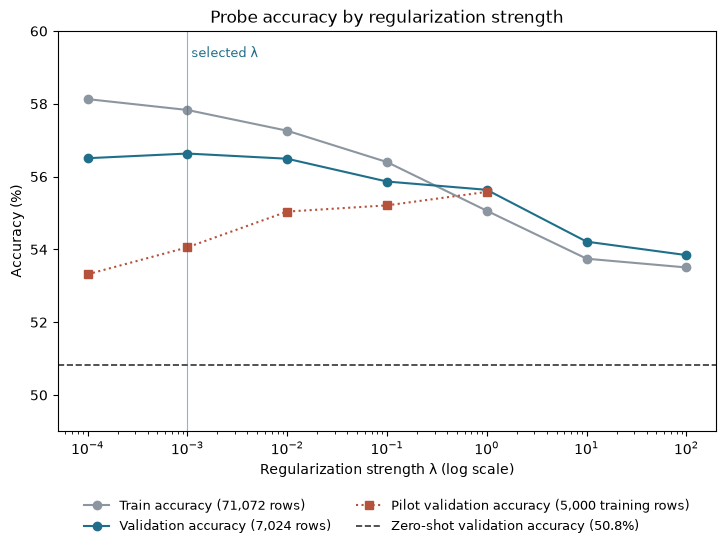

In [4]:
grid_lams = [g["lambda"] for g in probe["grid"]]
pilot_lams = [g["lambda"] for g in pilot["grid"]]
pilot_val = [100 * g["val"]["accuracy"] for g in pilot["grid"]]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.plot(grid_lams, [100 * g["train"]["accuracy"] for g in probe["grid"]], marker="o",
        color="#8C96A0", label=f"Train accuracy ({probe['rows']['train']:,} rows)")
ax.plot(grid_lams, [100 * g["val"]["accuracy"] for g in probe["grid"]], marker="o",
        color="#1F6F8B", label=f"Validation accuracy ({probe['rows']['val']:,} rows)")
ax.plot(pilot_lams, pilot_val, marker="s", linestyle=":", color="#B5523B",
        label=f"Pilot validation accuracy ({pilot['rows']['train']:,} training rows)")
ax.axhline(100 * probe["zero_shot_val_accuracy"], linestyle="--", color="#333333", linewidth=1.2,
           label=f"Zero-shot validation accuracy ({100 * probe['zero_shot_val_accuracy']:.1f}%)")
ax.axvline(selected, color="#1F6F8B", linewidth=0.8, alpha=0.5)
ax.text(selected, 59.2, " selected λ", color="#1F6F8B", fontsize=9, va="bottom")
ax.set_xscale("log")
ax.set_ylim(49, 60)
ax.set_xlabel("Regularization strength λ (log scale)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Probe accuracy by regularization strength")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.savefig(FIG / "04_regularization.png", dpi=200, bbox_inches="tight")
plt.show()

With 71,072 training rows, the train and validation accuracies are close, unlike the 5,000-row pilot. The regularization λ was chosen on validation only.

## Target results

In [5]:
targets = [
    ("NewsCLIPpings test (held-out)", probe["newsclippings_test"]),
    ("VERITE true vs out-of-context", probe["verite_true_vs_ooc"]),
]
arms = [("zero_shot", "LAYA zero-shot (own choice)"), ("probe", "Frozen-feature probe")]

target_rows = []
for target_name, block in targets:
    for arm_key, arm_label in arms:
        arm = block[arm_key]
        lo, hi = arm["accuracy_95"]
        target_rows.append({
            "Target": target_name,
            "Arm": arm_label,
            "Accuracy (%)": f"{100 * arm['accuracy']:.2f}",
            "95% range": f"[{100 * lo:.2f}, {100 * hi:.2f}]",
            "Balanced acc. (%)": f"{100 * arm['balanced_accuracy']:.2f}",
            "Macro-F1 (%)": f"{100 * arm['macro_f1']:.2f}",
            "AUC": f"{arm['auc']:.3f}",
            "ECE (%)": f"{100 * arm['ece_15']:.2f}",
            "Recall pristine (%)": f"{100 * arm['recall_pristine']:.2f}",
            "Recall falsified (%)": f"{100 * arm['recall_falsified']:.2f}",
        })
target_table = pd.DataFrame(target_rows)
display(target_table.set_index(["Target", "Arm"]))

for target_name, block in targets:
    diff = block["probe_minus_zero_shot"]
    dlo, dhi = diff["accuracy_95"]
    print(f"{target_name}: probe minus zero-shot {100 * diff['accuracy']:+.2f} pp, "
          f"95% range [{100 * dlo:+.2f}, {100 * dhi:+.2f}] pp, "
          f"range spans zero: {bool(dlo <= 0 <= dhi)}")

Accuracy (%)  \
Target                        Arm                                        
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)        51.13   
                              Frozen-feature probe               57.37   
VERITE true vs out-of-context LAYA zero-shot (own choice)        50.53   
                              Frozen-feature probe               54.90   

                                                                95% range  \
Target                        Arm                                           
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)  [50.10, 52.14]   
                              Frozen-feature probe         [56.26, 58.44]   
VERITE true vs out-of-context LAYA zero-shot (own choice)  [46.76, 54.45]   
                              Frozen-feature probe         [51.13, 58.52]   

                                                          Balanced acc. (%)  \
Target                        Arm                                             
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)             51.13   
                              Frozen-feature probe                    57.37   
VERITE true vs out-of-context LAYA zero-shot (own choice)             51.20   
                              Frozen-feature probe                    54.60   

                                                          Macro-F1 (%)    AUC  \
Target                        Arm                                               
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)        42.09  0.528   
                              Frozen-feature probe               57.36  0.598   
VERITE true vs out-of-context LAYA zero-shot (own choice)        44.34  0.544   
                              Frozen-feature probe               53.63  0.569   

                                                          ECE (%)  \
Target                        Arm                                   
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)   16.37   
                              Frozen-feature probe           1.12   
VERITE true vs out-of-context LAYA zero-shot (own choice)   15.98   
                              Frozen-feature probe           6.10   

                                                          Recall pristine (%)  \
Target                        Arm                                               
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)               11.62   
                              Frozen-feature probe                      56.97   
VERITE true vs out-of-context LAYA zero-shot (own choice)               16.86   
                              Frozen-feature probe                      70.12   

                                                          Recall falsified (%)  
Target                        Arm                                               
NewsCLIPpings test (held-out) LAYA zero-shot (own choice)                90.64  
                              Frozen-feature probe                       57.76  
VERITE true vs out-of-context LAYA zero-shot (own choice)                85.54  
                              Frozen-feature probe                       39.08

NewsCLIPpings test (held-out): probe minus zero-shot +6.24 pp, 95% range [+4.76, +7.70] pp, range spans zero: False
VERITE true vs out-of-context: probe minus zero-shot +4.37 pp, 95% range [-1.36, +9.95] pp, range spans zero: True


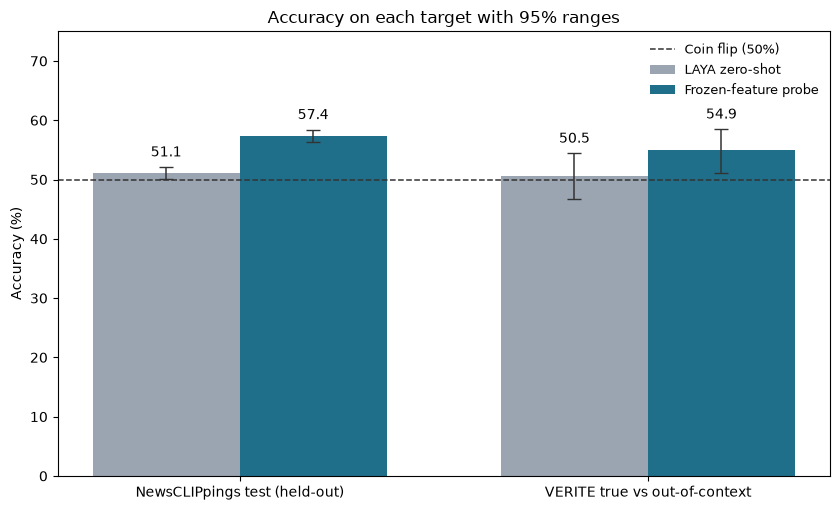

In [6]:
x = np.arange(len(targets))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 5.2))
styles = [("zero_shot", "LAYA zero-shot", "#9AA5B1", -width / 2),
          ("probe", "Frozen-feature probe", "#1F6F8B", width / 2)]
for arm_key, label, color, offset in styles:
    vals = [100 * block[arm_key]["accuracy"] for _, block in targets]
    lows = [100 * block[arm_key]["accuracy_95"][0] for _, block in targets]
    highs = [100 * block[arm_key]["accuracy_95"][1] for _, block in targets]
    err_lo = [v - lo for v, lo in zip(vals, lows)]
    err_hi = [hi - v for v, hi in zip(vals, highs)]
    ax.bar(x + offset, vals, width, yerr=[err_lo, err_hi], capsize=5, color=color,
           error_kw={"elinewidth": 1.1, "ecolor": "#333333"}, label=label)
    for xi, v, hi in zip(x + offset, vals, highs):
        ax.text(xi, hi + 1.2, f"{v:.1f}", ha="center", va="bottom", fontsize=10)
ax.axhline(50, linestyle="--", color="#333333", linewidth=1.1, label="Coin flip (50%)")
ax.set_xticks(x)
ax.set_xticklabels([name for name, _ in targets])
ax.set_ylim(0, 75)
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy on each target with 95% ranges")
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "04_targets.png", dpi=200, bbox_inches="tight")
plt.show()

## Per-group results

In [7]:
strategy_block = probe["newsclippings_test"]["by_source_dataset"]
strategy_rows = []
for key in sorted(strategy_block, key=int):
    group = strategy_block[key]
    strategy_rows.append({
        "source_dataset strategy": key,
        "n": f"{group['n']:,}",
        "Probe accuracy (%)": f"{100 * group['probe_accuracy']:.1f}",
        "Zero-shot accuracy (%)": f"{100 * group['zero_shot_accuracy']:.1f}",
        "Probe minus zero-shot (pp)": f"{100 * (group['probe_accuracy'] - group['zero_shot_accuracy']):+.1f}",
    })
print("NewsCLIPpings test, by source_dataset strategy")
display(pd.DataFrame(strategy_rows).set_index("source_dataset strategy"))

verite_block = probe["verite_true_vs_ooc"]
label_rows = []
for key in ["true", "out-of-context"]:
    group = verite_block["by_source_dataset"][key]
    label_rows.append({
        "VERITE label": key,
        "n": f"{group['n']:,}",
        "Probe accuracy (%)": f"{100 * group['probe_accuracy']:.1f}",
        "Zero-shot accuracy (%)": f"{100 * group['zero_shot_accuracy']:.1f}",
    })
print("VERITE true vs out-of-context, by label")
display(pd.DataFrame(label_rows).set_index("VERITE label"))
print(f"Share of VERITE rows called falsified: probe {100 * verite_block['probe']['predicted_falsified_share']:.1f}%, "
      f"zero-shot {100 * verite_block['zero_shot']['predicted_falsified_share']:.1f}%")

NewsCLIPpings test, by source_dataset strategy


,n,Probe accuracy (%),Zero-shot accuracy (%),Probe minus zero-shot (pp)
source_dataset strategy,,,,
0,"1,816",53.5,50.5,+3.0
1,"1,816",60.0,51.7,+8.4
2,"1,816",58.9,51.3,+7.5
3,"1,816",57.1,51.0,+6.1


VERITE true vs out-of-context, by label


,n,Probe accuracy (%),Zero-shot accuracy (%)
VERITE label,,,
true,338,70.1,16.9
out-of-context,325,39.1,85.5


Share of VERITE rows called falsified: probe 34.4%, zero-shot 84.3%


## Against published results (reference points, not a ranking)

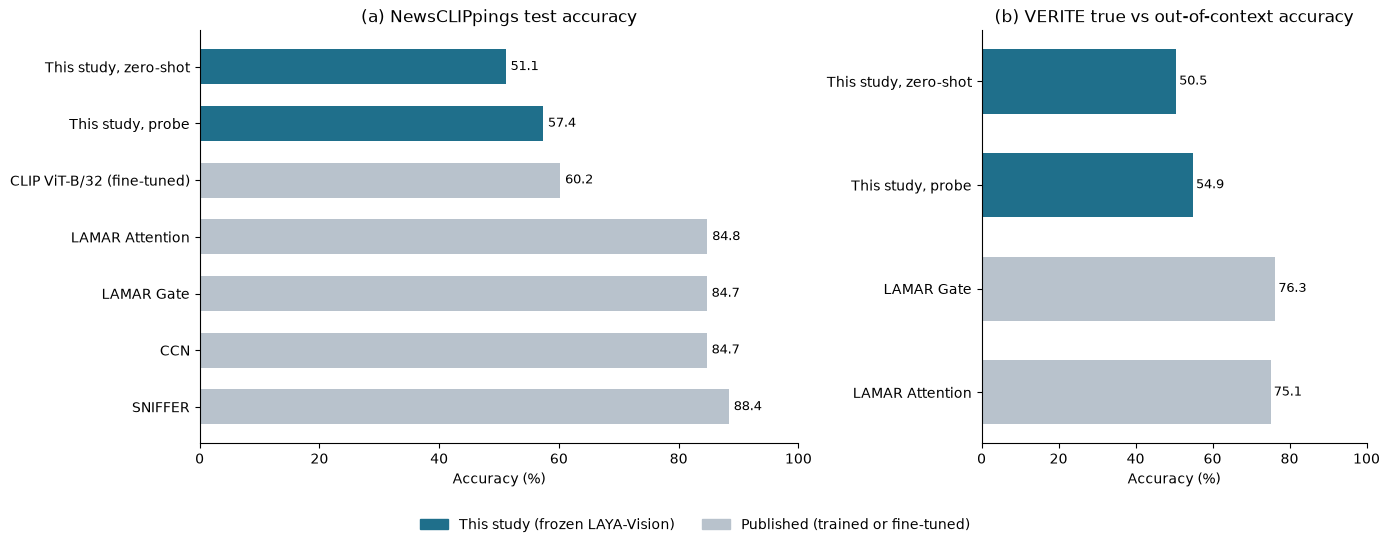

Accuracy (%)  \
Panel              System                         
NewsCLIPpings test CLIP ViT-B/32           60.2   
                   LAMAR Attention         84.8   
                   LAMAR Gate              84.7   
                   CCN                     84.7   
                   SNIFFER                 88.4   
VERITE true vs OOC LAMAR Gate              76.3   
                   LAMAR Attention         75.1   

                                                        Training regime (as recorded)  
Panel              System                                                              
NewsCLIPpings test CLIP ViT-B/32    both CLIP and VisualBERT models are fine-tuned...  
                   LAMAR Attention          trained end-to-end on NewsCLIPpings train  
                   LAMAR Gate               trained end-to-end on NewsCLIPpings train  
                   CCN              trained classifier with evidence retrieved fro...  
                   SNIFFER          two-stage instruction tuning on NewsCLIPpings-...  
VERITE true vs OOC LAMAR Gate               trained end-to-end on NewsCLIPpings train  
                   LAMAR Attention          trained end-to-end on NewsCLIPpings train

Probe gap to LAMAR Attention on NewsCLIPpings: 27.4 pp
Probe gap to LAMAR Gate on VERITE true vs OOC: 21.4 pp


In [8]:
def supplement_result(dataset, model_prefix, task_prefix=None):
    hits = []
    for entry in supplement["entries"]:
        if entry["dataset"] != dataset:
            continue
        if task_prefix is not None and not entry["task"].startswith(task_prefix):
            continue
        for result in entry["results"]:
            if result["model"].startswith(model_prefix):
                hits.append(result)
    assert len(hits) == 1, (dataset, model_prefix, len(hits))
    return hits[0]


clip_hits = [r for e in references["entries"] if e["dataset"] == "newsclippings"
             for r in e["results"] if r["model"].startswith("CLIP")]
assert len(clip_hits) == 1, len(clip_hits)
clip = clip_hits[0]

ccn = supplement_result("newsclippings", "CCN")
sniffer = supplement_result("newsclippings", "SNIFFER")
lamar_att_nc = supplement_result("newsclippings", "LAMAR [E2E, Attention]")
lamar_gate_nc = supplement_result("newsclippings", "LAMAR [E2E, Gate]")
lamar_att_vt = supplement_result("verite", "LAMAR [E2E, Attention]", task_prefix="binary True vs OOC")
lamar_gate_vt = supplement_result("verite", "LAMAR [E2E, Gate]", task_prefix="binary True vs OOC")

nc_block = probe["newsclippings_test"]
vt_block = probe["verite_true_vs_ooc"]
nc_zs = 100 * nc_block["zero_shot"]["accuracy"]
nc_pr = 100 * nc_block["probe"]["accuracy"]
vt_zs = 100 * vt_block["zero_shot"]["accuracy"]
vt_pr = 100 * vt_block["probe"]["accuracy"]

nc_bars = [
    ("This study, zero-shot", nc_zs, "study"),
    ("This study, probe", nc_pr, "study"),
    ("CLIP ViT-B/32 (fine-tuned)", 100 * clip["value"], "published"),
    ("LAMAR Attention", lamar_att_nc["value"], "published"),
    ("LAMAR Gate", lamar_gate_nc["value"], "published"),
    ("CCN", ccn["value"], "published"),
    ("SNIFFER", sniffer["value"], "published"),
]
vt_bars = [
    ("This study, zero-shot", vt_zs, "study"),
    ("This study, probe", vt_pr, "study"),
    ("LAMAR Gate", lamar_gate_vt["value"], "published"),
    ("LAMAR Attention", lamar_att_vt["value"], "published"),
]

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [7, 4.5]})
for ax, bars, title in [
    (ax_a, nc_bars, "(a) NewsCLIPpings test accuracy"),
    (ax_b, vt_bars, "(b) VERITE true vs out-of-context accuracy"),
]:
    labels = [b[0] for b in bars][::-1]
    values = [b[1] for b in bars][::-1]
    colors = ["#1F6F8B" if b[2] == "study" else "#B8C2CC" for b in bars][::-1]
    positions = np.arange(len(bars))
    ax.barh(positions, values, color=colors, height=0.62)
    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    for pos, v in zip(positions, values):
        ax.text(v + 0.8, pos, f"{v:.1f}", va="center", fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Accuracy (%)")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
legend_items = [Patch(color="#1F6F8B", label="This study (frozen LAYA-Vision)"),
                Patch(color="#B8C2CC", label="Published (trained or fine-tuned)")]
fig.legend(handles=legend_items, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "04_published_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

published_rows = [
    {"Panel": "NewsCLIPpings test", "System": "CLIP ViT-B/32", "Accuracy (%)": f"{100 * clip['value']:.1f}",
     "Training regime (as recorded)": plain(clip["regime"].split(";")[0])},
    {"Panel": "NewsCLIPpings test", "System": "LAMAR Attention", "Accuracy (%)": f"{lamar_att_nc['value']:.1f}",
     "Training regime (as recorded)": plain(lamar_att_nc["regime"])},
    {"Panel": "NewsCLIPpings test", "System": "LAMAR Gate", "Accuracy (%)": f"{lamar_gate_nc['value']:.1f}",
     "Training regime (as recorded)": plain(lamar_gate_nc["regime"])},
    {"Panel": "NewsCLIPpings test", "System": "CCN", "Accuracy (%)": f"{ccn['value']:.1f}",
     "Training regime (as recorded)": plain(ccn["regime"])},
    {"Panel": "NewsCLIPpings test", "System": "SNIFFER", "Accuracy (%)": f"{sniffer['value']:.1f}",
     "Training regime (as recorded)": plain(sniffer["regime"])},
    {"Panel": "VERITE true vs OOC", "System": "LAMAR Gate", "Accuracy (%)": f"{lamar_gate_vt['value']:.1f}",
     "Training regime (as recorded)": plain(lamar_gate_vt["regime"])},
    {"Panel": "VERITE true vs OOC", "System": "LAMAR Attention", "Accuracy (%)": f"{lamar_att_vt['value']:.1f}",
     "Training regime (as recorded)": plain(lamar_att_vt["regime"])},
]
display(pd.DataFrame(published_rows).set_index(["Panel", "System"]))

gap_nc = lamar_att_nc["value"] - nc_pr
gap_vt = lamar_gate_vt["value"] - vt_pr
print(f"Probe gap to LAMAR Attention on NewsCLIPpings: {gap_nc:.1f} pp")
print(f"Probe gap to LAMAR Gate on VERITE true vs OOC: {gap_vt:.1f} pp")

In [9]:
best = max(probe["grid"], key=lambda g: (g["val"]["accuracy"], g["lambda"]))
assert probe["integrity_gate"]["passed"] is True
assert probe["reproducibility"]["passed"] is True
assert best["lambda"] == probe["selected_lambda"], (best["lambda"], probe["selected_lambda"])
assert probe["rows"] == {"train": 71072, "val": 7024, "test": 7264, "verite": 663}, probe["rows"]
print("all checks passed")

all checks passed


## Takeaways

- Held-out NewsCLIPpings test: the probe reaches 57.4% against 51.1% for zero-shot on the same 7,264 rows, a gain of 6.24 pp with a 95% range of [4.76, 7.70] pp.
- Calibration and balance: ECE falls from 16.4% to 1.1%. Recall on pristine pairs rises from 11.6% to 57.0%, and recall on falsified pairs falls from 90.6% to 57.8%.
- VERITE true vs out-of-context: the probe reaches 54.9% against 50.5% for zero-shot, a gain of 4.37 pp with a 95% range of [-1.36, 9.95] pp. That range spans zero, so this result does not separate the probe from zero-shot. The two arms fail in opposite directions.
- Distance to the stretch targets: the probe is 27.4 pp below LAMAR Attention (84.8) on NewsCLIPpings and 21.4 pp below LAMAR Gate (76.3) on VERITE. Both targets are not met.